In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('blinkit_data.csv')

In [3]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [4]:
df.shape

(8523, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [6]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.857645,140.992782,3.965857
std,8.371760,0.051598,4.643456,62.275067,0.605651
min,1998.000000,0.000000,4.555000,31.290000,1.000000
25%,2000.000000,0.026989,8.773750,93.826500,4.000000
50%,2012.000000,0.053931,12.600000,143.012800,4.000000
75%,2017.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [7]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [9]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['Item Weight'].median()

12.6

In [12]:
df['Item Weight'].fillna(df['Item Weight'].median(), inplace=True)

In [13]:
df.isnull().sum()

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64

In [14]:
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [15]:
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

In [16]:
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

In [17]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Item Fat Content
Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Item Identifier
Item Identifier
FDW13    10
FDG33    10
FDF56     9
FDF52     9
FDV38     9
         ..
FDK57     1
FDO33     1
DRF48     1
FDC23     1
FDE52     1
Name: count, Length: 1559, dtype: int64

Item Type
Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Outlet Identifier
Outlet Identifier
OUT027    935
OUT013    932
OUT049    930
OUT046    930
OUT035    930
OUT045    929
OUT018    928
OUT017    926
OUT010    555
OUT019    52

In [18]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,8523.00000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.81342,140.992782,3.965857
std,8.371760,0.051598,4.22724,62.275067,0.605651
min,1998.000000,0.000000,4.55500,31.290000,1.000000
25%,2000.000000,0.026989,9.31000,93.826500,4.000000
50%,2012.000000,0.053931,12.60000,143.012800,4.000000
75%,2017.000000,0.094585,16.00000,185.643700,4.200000
max,2022.000000,0.328391,21.35000,266.888400,5.000000


In [19]:
(df['Item Visibility'] == 0).sum()

np.int64(526)

In [20]:
visibility_median = df.loc[df['Item Visibility'] != 0, 'Item Visibility'].median()

visibility_median

0.057792343

In [21]:
df['Item Visibility'] = df['Item Visibility'].replace(0, visibility_median)

In [22]:
(df['Item Visibility'] == 0).sum()

np.int64(0)

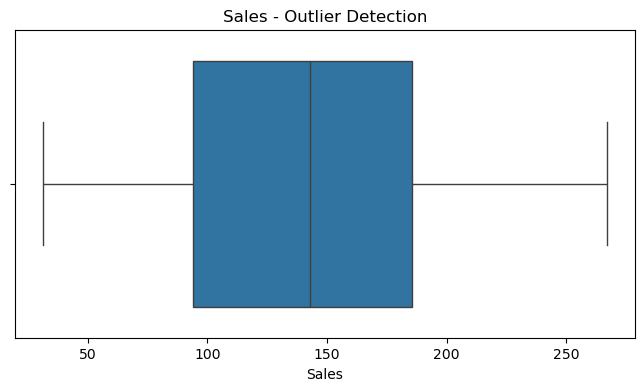

In [23]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Sales'])
plt.title('Sales - Outlier Detection')
plt.show()

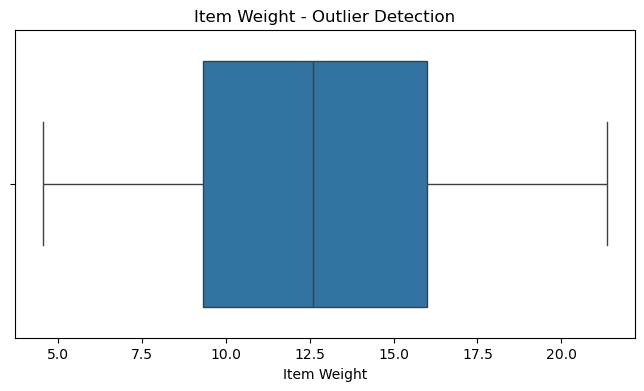

In [24]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Item Weight'])
plt.title('Item Weight - Outlier Detection')
plt.show()

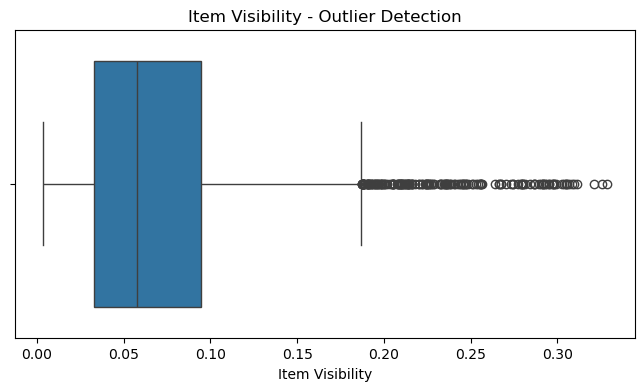

In [25]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Item Visibility'])
plt.title('Item Visibility - Outlier Detection')
plt.show()

In [26]:
Q1 = df['Item Visibility'].quantile(0.25)
Q3 = df['Item Visibility'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Item Visibility'] < lower_limit) |
    (df['Item Visibility'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Outliers:", len(outliers))

Lower Limit: -0.059164579999999994
Upper Limit: 0.186835216
Total Outliers: 173


In [27]:
outliers['Item Visibility'].describe()

count    173.000000
mean       0.235721
std        0.038537
min        0.187443
25%        0.204713
50%        0.226123
75%        0.266397
max        0.328391
Name: Item Visibility, dtype: float64

In [28]:
outliers[['Item Identifier', 'Item Visibility', 'Sales']].head(10)

,Item Identifier,Item Visibility,Sales
92,FDK02,0.196491,120.5440
93,FDI15,0.247490,263.1884
109,FDF56,0.209163,179.1976
294,FDR48,0.220111,153.0024
300,NCQ17,0.195721,156.4630
302,NCN06,0.201688,162.8868
303,NCF30,0.211307,125.1362
311,FDC60,0.191603,87.0514
312,FDJ36,0.214681,102.7332
313,FDU47,0.190569,138.7838


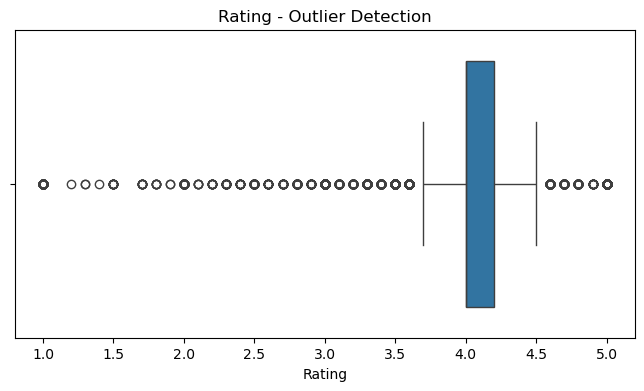

In [29]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Rating'])
plt.title('Rating - Outlier Detection')
plt.show()

In [30]:
Q1 = df['Rating'].quantile(0.25)
Q3 = df['Rating'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

rating_outliers = df[
    (df['Rating'] < lower_limit) |
    (df['Rating'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Outliers:", len(rating_outliers))

Lower Limit: 3.6999999999999997
Upper Limit: 4.5
Total Outliers: 1931


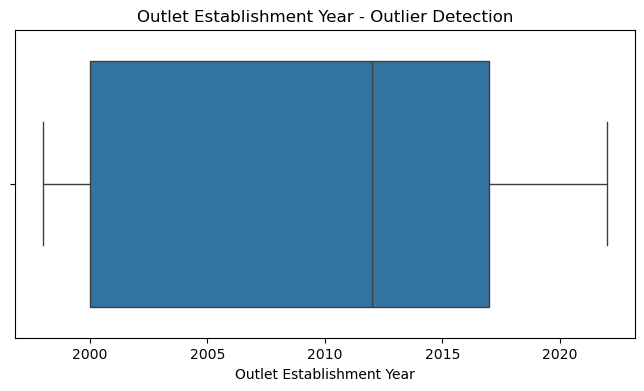

In [31]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Outlet Establishment Year'])
plt.title('Outlet Establishment Year - Outlier Detection')
plt.show()

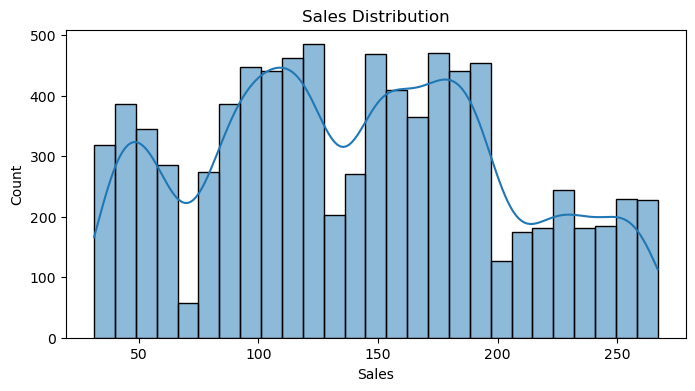

In [32]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Sales'], kde=True)
plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.show()

In [33]:
sales_by_item = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_item)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9204
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4596
Canned                    90706.7270
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1650
Breads                    35379.1198
Hard Drinks               29334.6766
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


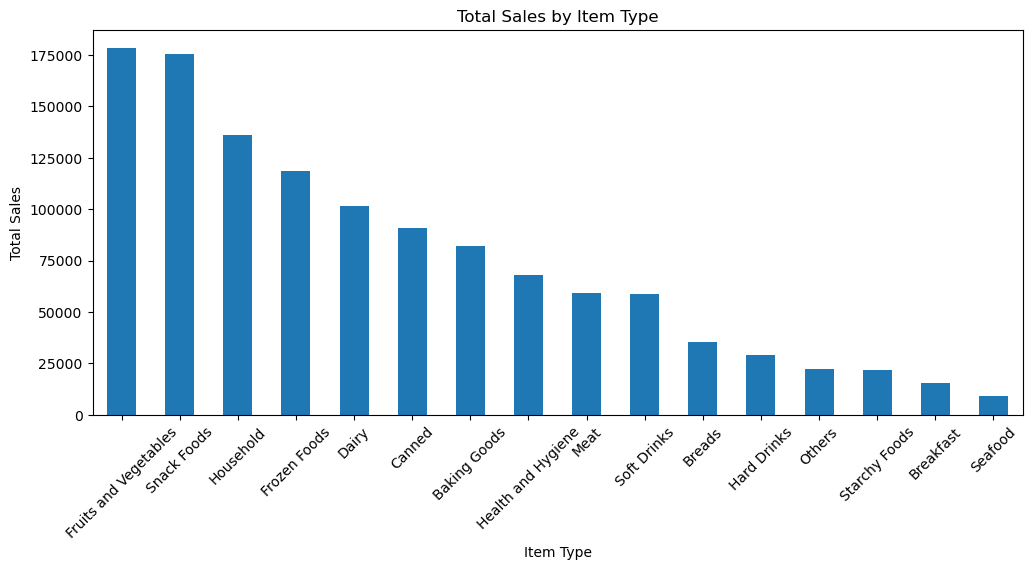

In [34]:
plt.figure(figsize=(12, 5))
sales_by_item.plot(kind='bar')

plt.title('Total Sales by Item Type')
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [35]:
sales_by_outlet = df.groupby('Outlet Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_outlet)

Outlet Type
Supermarket Type1    787549.8868
Grocery Store        151939.1470
Supermarket Type2    131477.7724
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


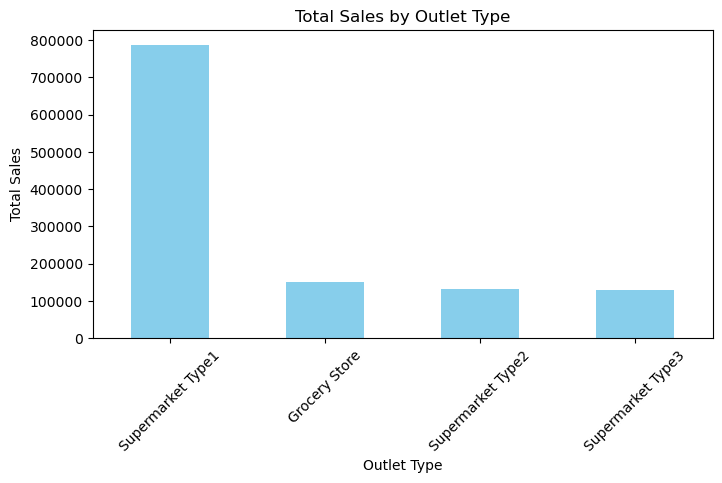

In [36]:
plt.figure(figsize=(8, 4))
sales_by_outlet.plot(kind='bar', color='skyblue')

plt.title('Total Sales by Outlet Type')
plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [37]:
sales_by_location = df.groupby('Outlet Location Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_location)

Outlet Location Type
Tier 3    472133.0272
Tier 2    393150.6416
Tier 1    336397.8120
Name: Sales, dtype: float64


In [38]:
sales_by_size = df.groupby('Outlet Size')['Sales'].sum().sort_values(ascending=False)

print(sales_by_size)

Outlet Size
Medium    507895.7284
Small     444794.1684
High      248991.5840
Name: Sales, dtype: float64


In [39]:
sales_by_year = df.groupby('Outlet Establishment Year')['Sales'].sum().sort_index()

print(sales_by_year)

Outlet Establishment Year
1998    204522.2570
2000    131809.0156
2010    132113.3698
2011     78131.5646
2012    130476.8598
2015    130942.7782
2017    133103.9070
2020    129103.9564
2022    131477.7724
Name: Sales, dtype: float64


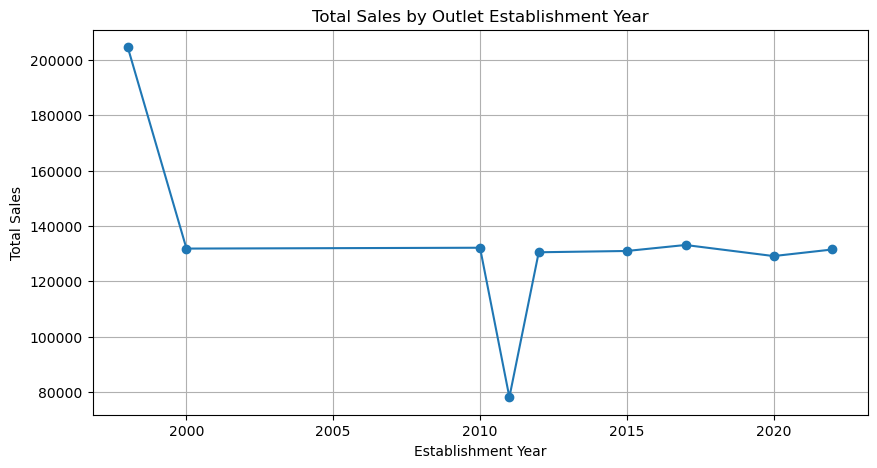

In [40]:
plt.figure(figsize=(10, 5))
sales_by_year.plot(kind='line', marker='o')

plt.title('Total Sales by Outlet Establishment Year')
plt.xlabel('Establishment Year')
plt.ylabel('Total Sales')
plt.grid()
plt.show()

In [41]:
sales_by_fat = df.groupby('Item Fat Content')['Sales'].sum()

print(sales_by_fat)

Item Fat Content
Low Fat    776319.6784
Regular    425361.8024
Name: Sales, dtype: float64


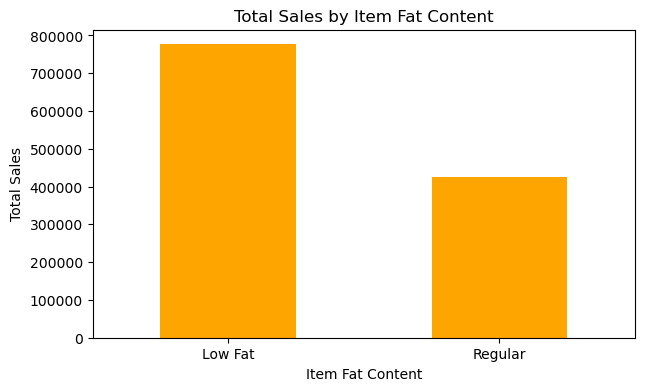

In [42]:
plt.figure(figsize=(7, 4))
sales_by_fat.plot(kind='bar', color='orange')

plt.title('Total Sales by Item Fat Content')
plt.xlabel('Item Fat Content')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [43]:
sales_by_rating = df.groupby('Rating')['Sales'].sum().sort_index()

print(sales_by_rating)

Rating
1.0     14930.7728
1.2       223.5404
1.3       266.1516
1.4       172.8396
1.5      1612.5334
1.7      1027.8584
1.8       753.4804
1.9       106.3306
2.0     10195.2296
2.1       373.3796
2.2      1368.2480
2.3      3610.6204
2.4      1583.4408
2.5      7358.1952
2.6      1974.1918
2.7      3061.0116
2.8      6826.5712
2.9      3558.8984
3.0     26753.7262
3.1      6755.9384
3.2      7694.6744
3.3     16485.8214
3.4     11967.7654
3.5     24021.8216
3.6     21003.6528
3.7     30335.7108
3.8     35110.2596
3.9     42981.2372
4.0    475733.6056
4.1     71333.3722
4.2     93304.8346
4.3     95714.5790
4.4     49537.8988
4.5     37460.5842
4.6     15478.0582
4.7     10819.1266
4.8      8691.3610
4.9      2211.6166
5.0     59282.5424
Name: Sales, dtype: float64


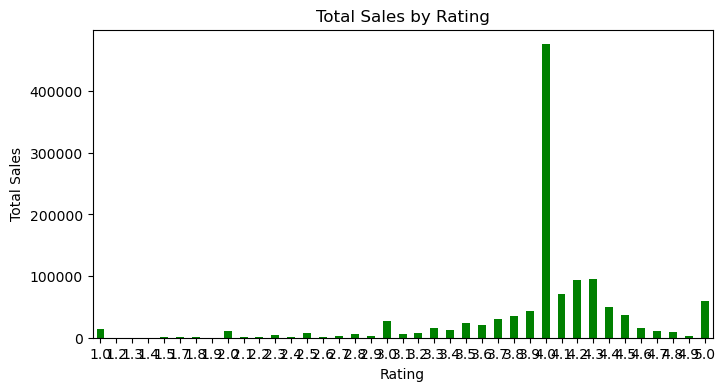

In [44]:
plt.figure(figsize=(8, 4))
sales_by_rating.plot(kind='bar', color='green')

plt.title('Total Sales by Rating')
plt.xlabel('Rating')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [45]:
avg_sales_by_rating = df.groupby('Rating')['Sales'].mean()

print(avg_sales_by_rating)

Rating
1.0    130.971691
1.2    223.540400
1.3    133.075800
1.4    172.839600
1.5    146.593945
1.7    128.482300
1.8    150.696080
1.9     53.165300
2.0    137.773373
2.1     93.344900
2.2    152.027556
2.3    138.870015
2.4    143.949164
2.5    153.295733
2.6    141.013700
2.7    145.762457
2.8    139.317780
2.9    148.287433
3.0    138.620343
3.1    137.876294
3.2    139.903171
3.3    136.246458
3.4    144.189945
3.5    140.478489
3.6    140.024352
3.7    143.771141
3.8    138.775730
3.9    142.321977
4.0    142.477869
4.1    136.132390
4.2    138.640170
4.3    137.917261
4.4    145.699702
4.5    146.330407
4.6    151.745669
4.7    136.950970
4.8    140.183242
4.9    147.441107
5.0    138.834994
Name: Sales, dtype: float64


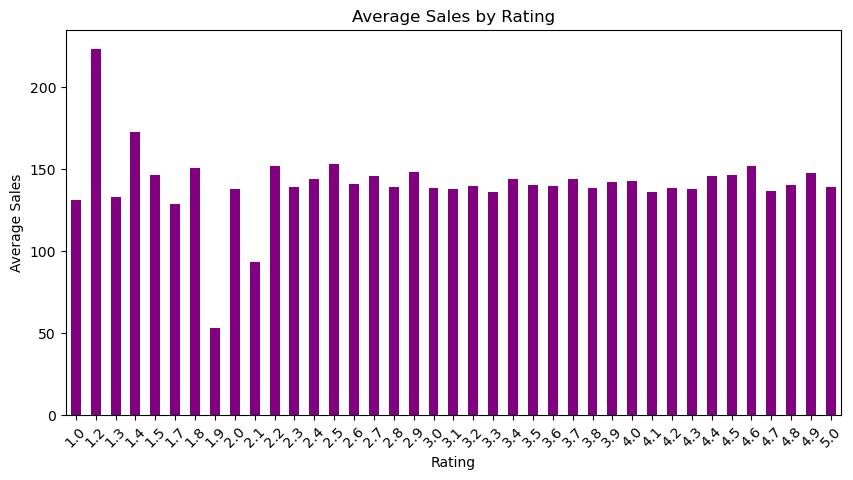

In [46]:
plt.figure(figsize=(10, 5))
avg_sales_by_rating.plot(kind='bar', color='purple')

plt.title('Average Sales by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()

In [47]:
rating_count = df.groupby('Rating').size()

print(rating_count)

Rating
1.0     114
1.2       1
1.3       2
1.4       1
1.5      11
1.7       8
1.8       5
1.9       2
2.0      74
2.1       4
2.2       9
2.3      26
2.4      11
2.5      48
2.6      14
2.7      21
2.8      49
2.9      24
3.0     193
3.1      49
3.2      55
3.3     121
3.4      83
3.5     171
3.6     150
3.7     211
3.8     253
3.9     302
4.0    3339
4.1     524
4.2     673
4.3     694
4.4     340
4.5     256
4.6     102
4.7      79
4.8      62
4.9      15
5.0     427
dtype: int64


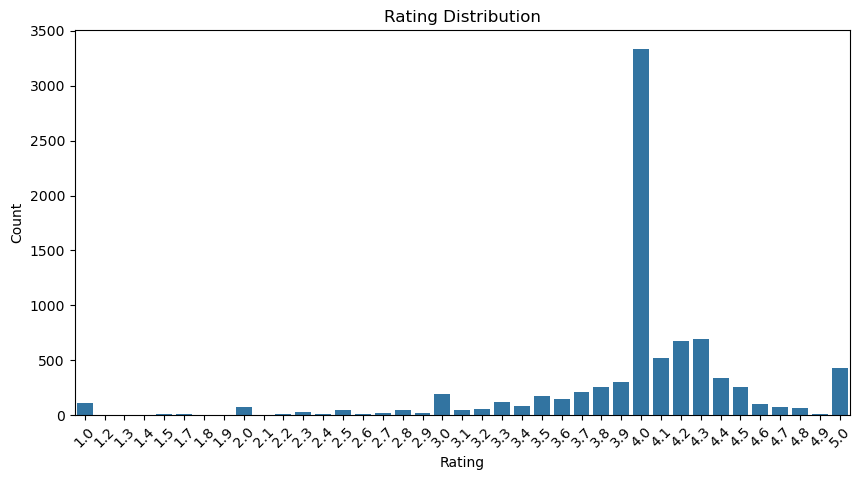

In [48]:
plt.figure(figsize=(10, 5))

sns.countplot(x='Rating', data=df)

plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [49]:
correlation = df.select_dtypes(include='number').corr()

print(correlation)

                           Outlet Establishment Year  Item Visibility  \
Outlet Establishment Year                   1.000000        -0.078328   
Item Visibility                            -0.078328         1.000000   
Item Weight                                 0.007739        -0.019065   
Sales                                       0.005020        -0.004763   
Rating                                      0.004489        -0.001529   

                           Item Weight     Sales    Rating  
Outlet Establishment Year     0.007739  0.005020  0.004489  
Item Visibility              -0.019065 -0.004763 -0.001529  
Item Weight                   1.000000  0.024951  0.002447  
Sales                         0.024951  1.000000  0.011329  
Rating                        0.002447  0.011329  1.000000  


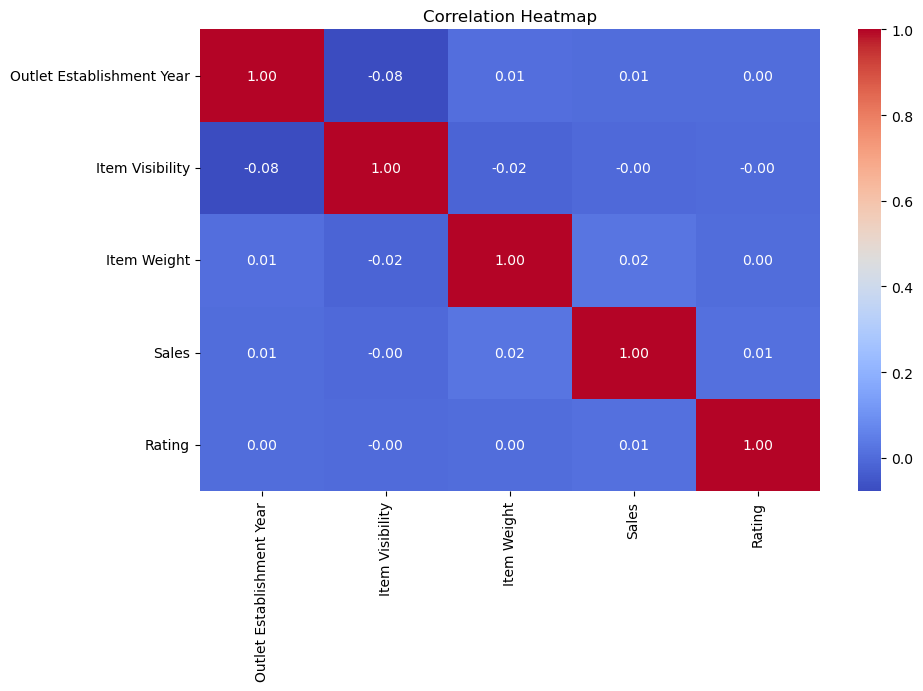

In [50]:
plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

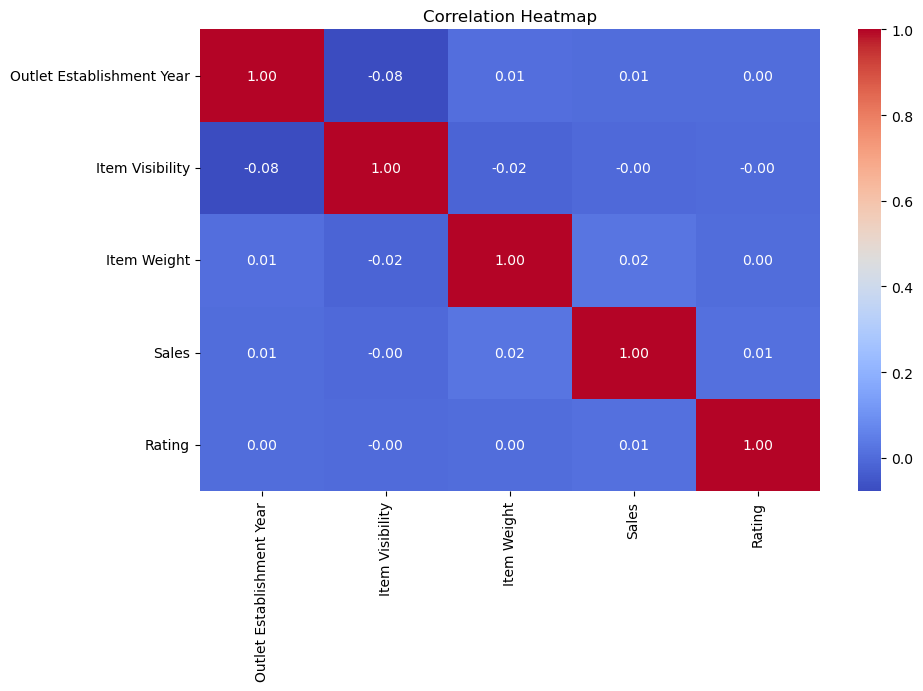

In [51]:
plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [52]:
X = df.drop('Sales', axis=1)

y = df['Sales']

In [53]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (8523, 11)
Target Shape: (8523,)


In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [55]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (6818, 11)
X_test: (1705, 11)
y_train: (6818,)
y_test: (1705,)


In [56]:
categorical_cols = X.select_dtypes(include=['object']).columns

numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Categorical Columns:")
print(list(categorical_cols))

print("\nNumerical Columns:")
print(list(numerical_cols))

Categorical Columns:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type']

Numerical Columns:
['Outlet Establishment Year', 'Item Visibility', 'Item Weight', 'Rating']


In [57]:
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [58]:
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

In [59]:
print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

X_train_encoded: (6818, 1586)
X_test_encoded: (1705, 1586)


In [60]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_encoded, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [61]:
y_pred = model.predict(X_test_encoded)

print(y_pred[:10])

[177.740478 130.811116 216.070186 176.886844 107.990616  79.962108
  87.078946 100.827584 143.05013  121.00009 ]


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 16.693511380645166
MSE: 506.1291977489404
RMSE: 22.49731534536822
R2 Score: 0.872234933318851


In [63]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

print(comparison.head(10))

   Actual Sales  Predicted Sales
0      183.6634       177.740478
1      127.3362       130.811116
2      231.1668       216.070186
3      188.3898       176.886844
4      102.6332       107.990616
5       60.4194        79.962108
6       56.2930        87.078946
7       92.5436       100.827584
8      163.1236       143.050130
9      165.6500       121.000090


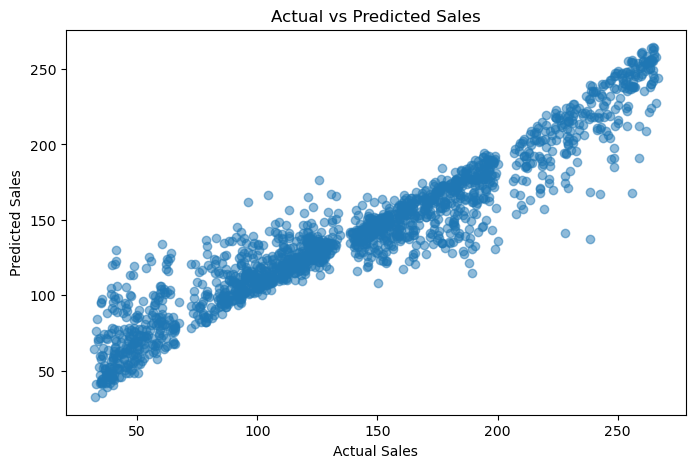

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

In [65]:
feature_importance = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(10))

                              Feature  Importance
1                     Item Visibility    0.069013
2                         Item Weight    0.063485
3                              Rating    0.013175
4            Item Fat Content_Regular    0.006340
1560  Item Type_Fruits and Vegetables    0.004878
1567            Item Type_Snack Foods    0.004782
1558                  Item Type_Dairy    0.004515
863             Item Identifier_FDR59    0.004315
1563              Item Type_Household    0.004231
1559           Item Type_Frozen Foods    0.004152


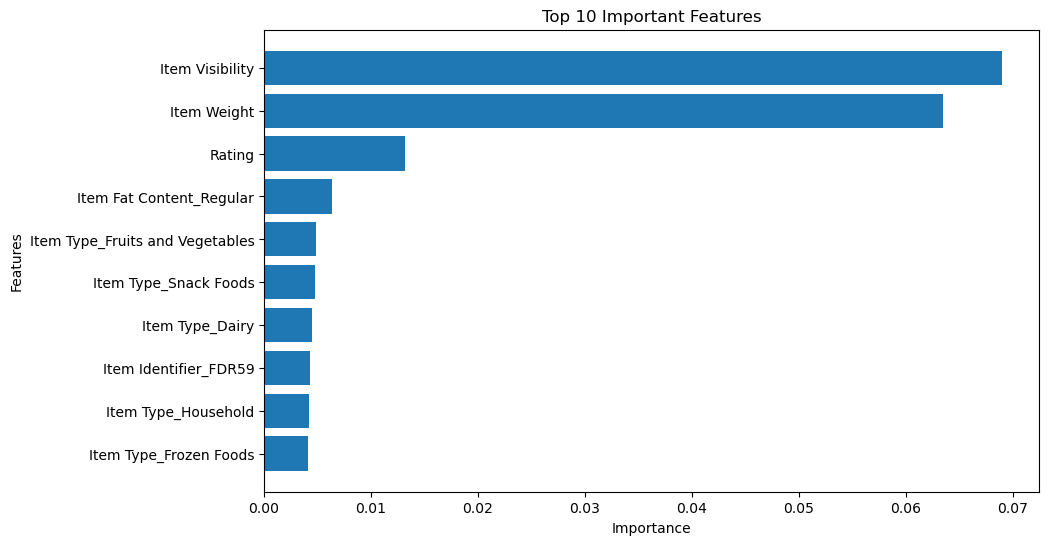

In [66]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(10)['Feature'],
    feature_importance.head(10)['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()
plt.show()

## Project Conclusion

In this project, I performed data cleaning, exploratory data analysis (EDA), and sales prediction using Machine Learning.

I handled missing values, removed inconsistent values, and analyzed sales trends using different visualizations.

I built a **Random Forest Regression Model** to predict sales.

### Model Evaluation
- MAE: 16.69
- MSE: 506.13
- RMSE: 22.50
- R² Score: 0.8722 (87.22%)

The model achieved an R² score of 87.22%, showing good performance on the test dataset.

Feature importance analysis showed that Item Visibility and Item Weight were the most important features for sales prediction.

**Conclusion:** This project helped me understand data preprocessing, data visualization, and machine learning model building.